# 01 数据体检：缺失值、重复记录、字段类型、异常情况
对应任务：**检查缺失值、重复记录、字段类型和异常情况**
本 notebook 只做"体检"，不改数据。所有结论都在下面用代码直接算出来，
没有靠经验假设——出现与常见说法不一致的地方，我会单独标出来。
数据来源：`data/raw/train.csv`、`data/raw/test.csv`（由 `preprocess.find_data_dir()` 自动定位）



In [1]:
import os
import sys
from pathlib import Path

# 从 Notebook 或分析源码所在位置向上定位项目根目录
START = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
ROOT = next(p for p in [START, *START.parents]
            if (p / "src" / "preprocess.py").is_file())
sys.path.insert(0, str(ROOT))
from src.paths import EXPERIMENTS_DIR, FIGURES_DIR
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")          # 沙箱里 joblib 探测核数会失败
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplcache"))

FIG = FIGURES_DIR
FIG.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from src import preprocess as pp

# 中文字体：默认字体没有汉字，标题会变成方框
matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
matplotlib.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Microsoft YaHei")

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

print("项目根目录:", ROOT)
print("数据目录  :", pp.find_data_dir())
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)



项目根目录: E:\github code\Titanic\Titanic-508
数据目录  : E:\github code\Titanic\Titanic-508\data\raw
pandas 3.0.5 | numpy 2.5.2 | matplotlib 3.11.1


## 1.1 规模与字段类型
先确认拿到的数据规模与题目描述一致（train 约 8700、test 约 4300），
再看每列的 dtype。**这里有个坑**：`CryoSleep` 和 `VIP` 在 CSV 里是
`True`/`False`/空，pandas 会读成 `object` 而不是 `bool`——因为真正的
`bool` 列不能带缺失值。它们是"三态"列，处理时要意识到这一点。



In [2]:
train_raw, test_raw = pp.load_raw()
print("train:", train_raw.shape, "| test:", test_raw.shape)
print("列差异:", set(train_raw.columns) ^ set(test_raw.columns))

dtype_tbl = pd.DataFrame({
    "train_dtype": train_raw.dtypes.astype(str),
    "test_dtype": test_raw.dtypes.astype(str),
})
shared = [c for c in dtype_tbl.index if c in test_raw.columns]
print("\n共有列 dtype 是否一致:", (dtype_tbl.loc[shared, "train_dtype"]
                                == dtype_tbl.loc[shared, "test_dtype"]).all())
print("test 缺少的列（即标签列）:", sorted(set(train_raw.columns) - set(test_raw.columns)))
print("\n各字段类型分布(train):")
print(train_raw.dtypes.astype(str).value_counts().to_string())
print("\nobject 类型列(可带缺失的三态列):",
      [c for c in train_raw.columns if train_raw[c].dtype == object])

pp.basic_report(train_raw)



train: (8693, 14) | test: (4277, 13)
列差异: {'Transported'}

共有列 dtype 是否一致: True
test 缺少的列（即标签列）: ['Transported']

各字段类型分布(train):
float64    6
str        5
object     2
bool       1

object 类型列(可带缺失的三态列): ['CryoSleep', 'VIP']


,列名,dtype,非空数,缺失数,缺失率%,唯一值,示例
0,PassengerId,str,8693,0,0.00,8693,"0001_01, 0002_01, 0003_01"
1,HomePlanet,str,8492,201,2.31,3,"Europa, Earth, Mars"
2,CryoSleep,object,8476,217,2.50,2,"False, True"
3,Cabin,str,8494,199,2.29,6560,"B/0/P, F/0/S, A/0/S"
4,Destination,str,8511,182,2.09,3,"TRAPPIST-1e, PSO J318.5-22, 55 Cancri e"
5,Age,float64,8514,179,2.06,80,"39.0, 24.0, 58.0"
6,VIP,object,8490,203,2.34,2,"False, True"
7,RoomService,float64,8512,181,2.08,1273,"0.0, 109.0, 43.0"
8,FoodCourt,float64,8510,183,2.11,1507,"0.0, 9.0, 3576.0"
9,ShoppingMall,float64,8485,208,2.39,1115,"0.0, 25.0, 371.0"


## 1.2 重复记录
两种情况分开查：**整行完全重复**（重复录入）和**主键 `PassengerId` 重复**（违反唯一性）。
另外还查列名重复。



In [3]:
for name, df in [("train", train_raw), ("test", test_raw)]:
    print(name, pp.duplicate_report(df))



train {'行数': 8693, '整行完全重复': 0, 'PassengerId 重复': 0, '列名重复': 0}
test {'行数': 4277, '整行完全重复': 0, 'PassengerId 重复': 0, '列名重复': 0}


## 1.3 PassengerId 结构解析
题目描述里 `gggg_pp` 的含义是"`gggg` 为同行组号，`pp` 为组内编号"。
验证格式是否 100% 成立，并看组规模分布——组规模后面会证明它和目标强相关。



In [4]:
train = pp.ensure_ids(train_raw.copy())
test = pp.ensure_ids(test_raw.copy())

for name, df in [("train", train), ("test", test)]:
    g = df.groupby("GroupId", observed=True).size()
    print(f"{name}: 行数={len(df)} 组数={len(g)} 组规模 1~{g.max()} "
          f"| 组内编号取值={sorted(df.GroupNum.unique())}")

print("\ntrain/test 组号交集:", len(set(train.GroupId) & set(test.GroupId)),
      "-> 两组完全独立，用同组信息补缺不会把 test 信息带进 train")

print("\n组规模分布(train):")
sizes = train.groupby("GroupId", observed=True).size()
print(pd.DataFrame({"组数": sizes.value_counts().sort_index(),
                    "占人数比例%": (sizes.value_counts().sort_index().index *
                                 sizes.value_counts().sort_index() / len(train) * 100).round(1)
                    }).to_string())



train: 行数=8693 组数=6217 组规模 1~8 | 组内编号取值=[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
test: 行数=4277 组数=3063 组规模 1~8 | 组内编号取值=[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

train/test 组号交集: 0 -> 两组完全独立，用同组信息补缺不会把 test 信息带进 train

组规模分布(train):
     组数  占人数比例%
1  4805    55.3
2   841    19.3
3   340    11.7
4   103     4.7
5    53     3.0
6    29     2.0
7    33     2.7
8    13     1.2


## 1.4 缺失值总览
**关键观察：每一列的缺失率都在 2% 左右，非常均匀。**
这说明各列缺失较为零散，不能仅凭此判断缺失机制完全随机。



train 缺失总览:
              缺失数  缺失率%    dtype
CryoSleep     217  2.50   object
ShoppingMall  208  2.39  float64
VIP           203  2.34   object
HomePlanet    201  2.31      str
Name          200  2.30      str
Cabin         199  2.29      str
VRDeck        188  2.16  float64
FoodCourt     183  2.11  float64
Spa           183  2.11  float64
Destination   182  2.09      str
RoomService   181  2.08  float64
Age           179  2.06  float64

含缺失的行: 2087 / 8693  (24.0%)
完全无缺失的行: 6606


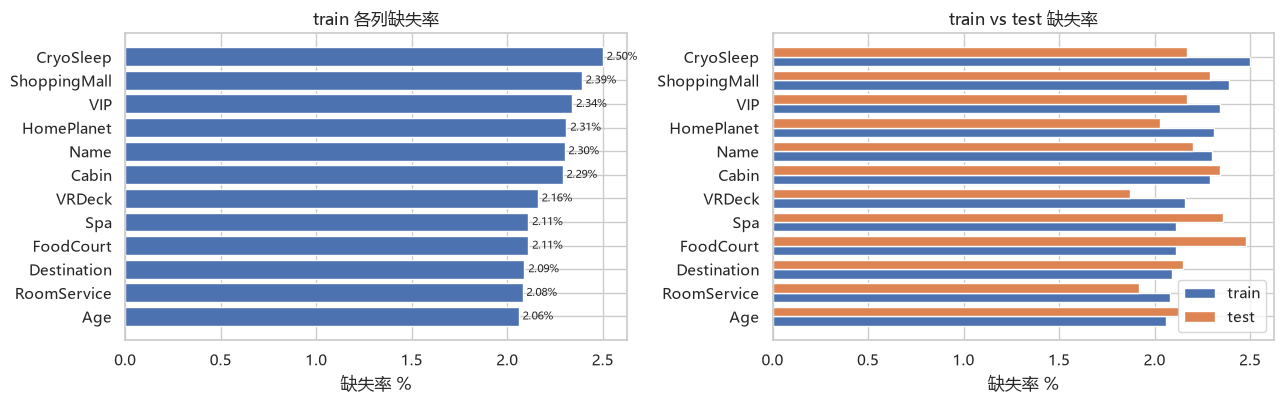

In [5]:
miss_tbl = pp.missing_summary(train_raw)
print("train 缺失总览:")
print(miss_tbl.to_string())
print(f"\n含缺失的行: {int(train_raw.isna().any(axis=1).sum())} / {len(train_raw)}"
      f"  ({train_raw.isna().any(axis=1).mean()*100:.1f}%)")
print(f"完全无缺失的行: {int((~train_raw.isna().any(axis=1)).sum())}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
m = miss_tbl["缺失率%"].sort_values()
axes[0].barh(m.index, m.values, color="#4C72B0")
axes[0].set_xlabel("缺失率 %")
axes[0].set_title("train 各列缺失率")
for i, v in enumerate(m.values):
    axes[0].text(v + 0.02, i, f"{v:.2f}%", va="center", fontsize=8)

mt = pp.missing_summary(test_raw)["缺失率%"].reindex(m.index)
w = 0.4
pos = np.arange(len(m))
axes[1].barh(pos - w / 2, m.values, height=w, label="train", color="#4C72B0")
axes[1].barh(pos + w / 2, mt.values, height=w, label="test", color="#DD8452")
axes[1].set_yticks(pos, m.index)
axes[1].set_xlabel("缺失率 %")
axes[1].set_title("train vs test 缺失率")
axes[1].legend()
plt.tight_layout()
fig.savefig(FIG / "01_missing_rate.png", dpi=140, bbox_inches="tight")
plt.show()



看一下缺失在行与行之间的分布形态：是"某几列一起缺"还是"各缺各的"。



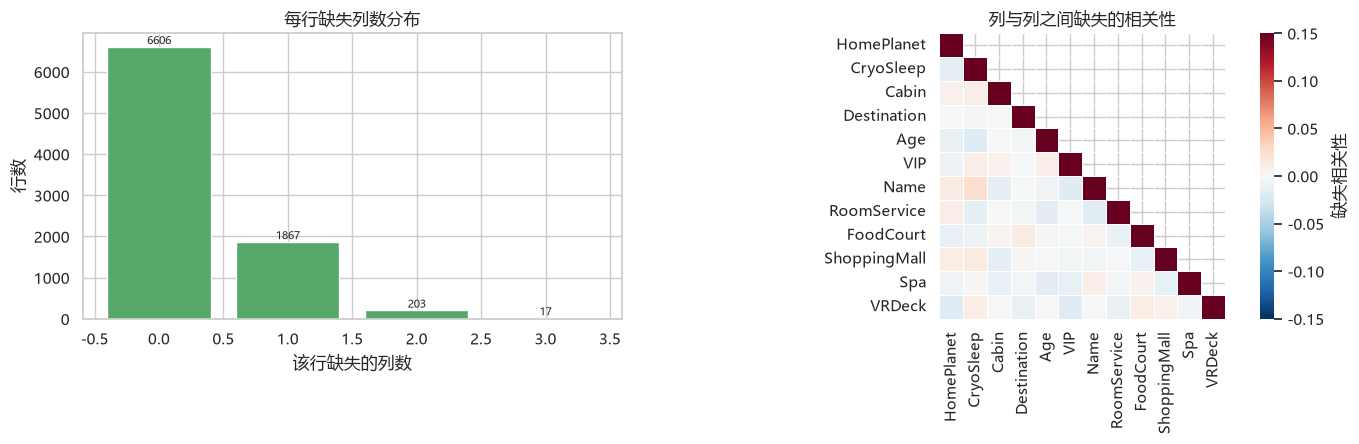

缺失相关性最高的 5 对：
Name          CryoSleep       0.0246
CryoSleep     Name            0.0246
ShoppingMall  CryoSleep       0.0135
CryoSleep     ShoppingMall    0.0135
FoodCourt     Destination     0.0121

最大相关性仅 0.025 -> 缺失近似于各列各自独立，不存在强共现结构。


In [6]:
na = train_raw.isna()
cols_all = ["HomePlanet", "CryoSleep", "Cabin", "Destination", "Age", "VIP", "Name",
            "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})

cnt = na[cols_all].sum(axis=1).value_counts().sort_index()
axes[0].bar(cnt.index, cnt.values, color="#55A868")
axes[0].set_xlabel("该行缺失的列数")
axes[0].set_ylabel("行数")
axes[0].set_title("每行缺失列数分布")
for x, v in zip(cnt.index, cnt.values):
    axes[0].text(x, v, str(v), ha="center", va="bottom", fontsize=8)

corr = na[cols_all].astype(int).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-0.15, vmax=0.15,
            square=True, linewidths=0.4, cbar_kws={"label": "缺失相关性"},
            ax=axes[1])
axes[1].set_title("列与列之间缺失的相关性")
plt.tight_layout()
fig.savefig(FIG / "01_missing_pattern.png", dpi=140, bbox_inches="tight")
plt.show()

top = (corr.where(~np.eye(len(cols_all), dtype=bool))
       .stack().sort_values(ascending=False).head(5))
print("缺失相关性最高的 5 对：")
print(top.round(4).to_string())
print("\n最大相关性仅 %.3f -> 缺失近似于各列各自独立，不存在强共现结构。" % top.iloc[0])



再确认一下总缺失的分布：抽样 400 行画缺失矩阵，白色为缺失。



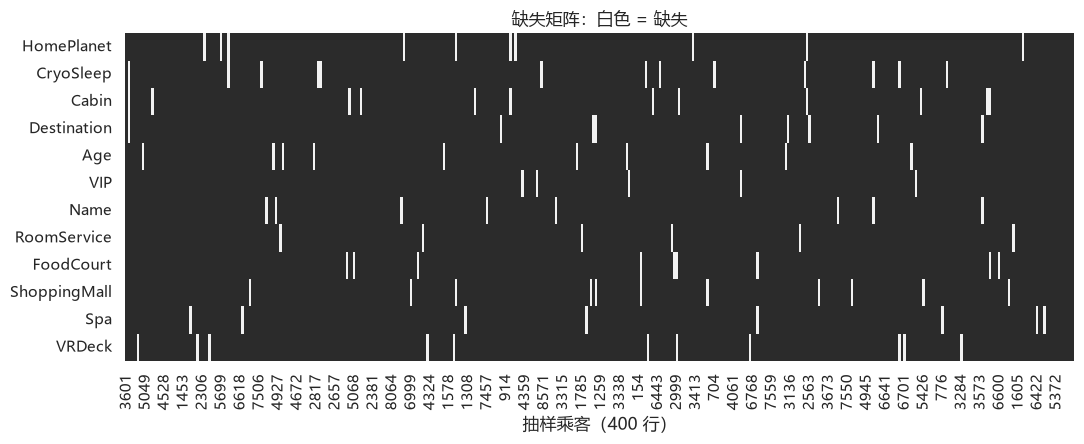

In [7]:
samp = train_raw[cols_all].sample(400, random_state=0).isna()
plt.figure(figsize=(11, 4.6))
sns.heatmap(samp.T, cbar=False, cmap=["#2b2b2b", "#f2f2f2"], yticklabels=True)
plt.xlabel("抽样乘客（400 行）")
plt.title("缺失矩阵：白色 = 缺失")
plt.tight_layout()
plt.savefig(FIG / "01_missing_matrix.png", dpi=140, bbox_inches="tight")
plt.show()



## 1.5 字段的组内一致性：哪些字段是"组级属性"
判断标准：同一个 `gggg` 组里的多个人，这一列是不是只有一个取值。
这决定了"能不能用同组其他人的值来补缺"，也决定了建模时哪些字段可以当组级特征。
这里只考察**有可能是组级属性**的字段。像 `Age`、`CryoSleep`、`VIP` 这类个人属性，
组内本来就该不同，放进来比较没有意义。
**结论与常见说法不一致，逐条看代码输出。**



In [8]:
train_full = pp.build_features(train_raw.copy())
print(pp.consistency_report(train_full).to_string(index=False))



         列名  多成员组数  组内取值>1 的组数
 HomePlanet   1412           0
Destination   1412         717
       Deck   1412         421
       Side   1412           0
    Surname   1412         249


In [9]:
print("=== 反例 1：同组 Destination 可以不同 ===")
gid = train_full.groupby("GroupId", observed=True).Destination.nunique(dropna=True)
gid = gid[gid > 1].index[0]
print(train_full[train_full.GroupId == gid]
      [["PassengerId", "HomePlanet", "Destination", "Cabin", "CryoSleep", "Transported"]]
      .to_string(index=False))

print("\n=== 反例 2：同组 Deck 可以不同（但 Side 相同） ===")
gid = train_full.groupby("GroupId", observed=True).Deck.nunique(dropna=True)
gid = gid[gid > 1].index[0]
print(train_full[train_full.GroupId == gid]
      [["PassengerId", "HomePlanet", "Destination", "Cabin", "Deck", "Side", "CabinNum"]]
      .to_string(index=False))

print("\n=== 反例 3：同组可以跨姓氏（拼组） ===")
gid = train_full.groupby("GroupId", observed=True).Surname.nunique(dropna=True)
gid = gid[gid > 1].index[0]
print(train_full[train_full.GroupId == gid]
      [["PassengerId", "Name", "Age", "Cabin", "Transported"]].to_string(index=False))



=== 反例 1：同组 Destination 可以不同 ===
PassengerId HomePlanet Destination Cabin  CryoSleep  Transported
    0008_01     Europa 55 Cancri e B/1/P       True         True
    0008_02     Europa TRAPPIST-1e B/1/P       True         True
    0008_03     Europa 55 Cancri e B/1/P      False         True

=== 反例 2：同组 Deck 可以不同（但 Side 相同） ===
PassengerId HomePlanet Destination Cabin Deck Side  CabinNum
    0006_01      Earth TRAPPIST-1e F/2/S    F    S       2.0
    0006_02      Earth TRAPPIST-1e G/0/S    G    S       0.0

=== 反例 3：同组可以跨姓氏（拼组） ===
PassengerId               Name  Age Cabin  Transported
    0020_01  Almary Brantuarez  1.0 E/0/S        False
    0020_02  Glendy Brantuarez 49.0 E/0/S        False
    0020_03 Mollen Mcfaddennon 29.0 E/0/S        False
    0020_04 Breney Jacostanley 10.0 E/0/S         True
    0020_05    Mael Brantuarez  1.0 E/0/S        False
    0020_06  Terta Mcfaddennon  7.0 E/0/S        False


三条反例说明：
| 字段 | 组内是否恒定 | 含义 |
|---|---|---|
| `HomePlanet` | ✅ 恒定（0 组例外） | 组级属性，可用同组补缺 |
| `Cabin` 的 `Side` | ✅ 恒定（0 组例外） | 组级属性 |
| `Cabin` 的 `Deck` / `Num` | ❌ 可不同 | 同组可能分在不同舱位 |
| `Destination` | ❌ 可不同 | **不是组级属性**，别拿同组去补 |
| `Surname` | ❌ 组内可多姓 | 姓氏与组号是两套信息，互补而非等价 |
后续补缺方案就按这张表来设计：`HomePlanet`/`Side` 用同组补，
`Destination`/`Deck` 只能退到全局众数。



## 1.6 异常情况检查
逐项验证：年龄、消费的取值范围，以及题目描述里那条"冷冻睡眠乘客待在自己舱内"
是否在数据上表现为**消费恒为 0**。



In [10]:
spend = pp.SPEND_COLS

print("=== 年龄 ===")
print(f"范围 {train_raw.Age.min()}~{train_raw.Age.max()} | 缺失 {train_raw.Age.isna().sum()}")
print(f"Age==0 的人数: {(train_raw.Age == 0).sum()} | 其中 CryoSleep=True: "
      f"{int(((train_raw.Age == 0) & (train_raw.CryoSleep == True)).sum())}")
print("-> Age==0 是婴儿，且与同组的成人年龄连贯，属于真实取值，不是脏数据")
gid = train_full[train_full.Age == 0].GroupId.iloc[0]
print(train_full[train_full.GroupId == gid][["PassengerId", "Age", "Name"]].to_string(index=False))

print("\n=== 消费列 ===")
print(f"负值个数: {int((train_raw[spend] < 0).sum().sum())} | 全 NaN 行: 0")
print("取值范围(max):")
print(train_raw[spend].max().to_string())
print("\n分布形态（右偏严重，中位数为 0）：")
print(train_raw[spend].describe().round(1).to_string())



=== 年龄 ===
范围 0.0~79.0 | 缺失 179
Age==0 的人数: 178 | 其中 CryoSleep=True: 71
-> Age==0 是婴儿，且与同组的成人年龄连贯，属于真实取值，不是脏数据
PassengerId  Age            Name
    0017_01  0.0   Lyde Brighttt
    0017_02 14.0 Philda Brighttt

=== 消费列 ===
负值个数: 0 | 全 NaN 行: 0
取值范围(max):
RoomService     14327.0
FoodCourt       29813.0
ShoppingMall    23492.0
Spa             22408.0
VRDeck          24133.0

分布形态（右偏严重，中位数为 0）：
       RoomService  FoodCourt  ShoppingMall      Spa   VRDeck
count       8512.0     8510.0        8485.0   8510.0   8505.0
mean         224.7      458.1         173.7    311.1    304.9
std          666.7     1611.5         604.7   1136.7   1145.7
min            0.0        0.0           0.0      0.0      0.0
25%            0.0        0.0           0.0      0.0      0.0
50%            0.0        0.0           0.0      0.0      0.0
75%           47.0       76.0          27.0     59.0     46.0
max        14327.0    29813.0       23492.0  22408.0  24133.0


**题目描述里那条规则的验证**：`CryoSleep=True` 的乘客"被限制在客舱内"，
对应到数据上应该是"五项消费全为 0"。反过来，花钱的人必定不在冷冻睡眠里。
这是我后面补缺方案的主要依据，所以必须逐条验证，不能想当然。



In [11]:
total_all = train_raw[spend].sum(axis=1, min_count=1)
cryo_true = train_raw.CryoSleep == True
allzero = total_all.fillna(0) == 0

print("规则 R2: CryoSleep=True 共 %d 人" % cryo_true.sum())
print(f"  其中消费非 0 的: {int((cryo_true & (total_all > 0)).sum())}  -> 规则成立(0 例外)")

print("\n规则 R1（反向推断）: 消费>0 的人 %d 个" % int((total_all > 0).sum()))
print(f"  其中 CryoSleep 明确为 True 的: {int(((total_all > 0) & cryo_true).sum())}  -> 规则成立")
print(f"  其中 CryoSleep 缺失的: {int(((total_all > 0) & train_raw.CryoSleep.isna()).sum())}"
      f"  -> 这 {int(((total_all > 0) & train_raw.CryoSleep.isna()).sum())} 人可以确定为 False")

print("\n消费全为 0 的人共 %d，其中 CryoSleep=True 的 %d、False 的 %d、缺失的 %d"
      % (allzero.sum(), int((allzero & cryo_true).sum()),
         int((allzero & (train_raw.CryoSleep == False)).sum()),
         int((allzero & train_raw.CryoSleep.isna()).sum())))
print("-> 消费全 0 有一半以上来自冷冻睡眠，但也有人既不冷冻也不消费，不能反推")

print("\n=== VIP ===")
vip = train_raw.VIP == True
print(f"VIP=True 共 {vip.sum()} 人")
print(f"  其中消费全为 0: {int((vip & allzero).sum())}（含冷冻睡眠 {int((vip & allzero & cryo_true).sum())} 人）")
print(f"  VIP=True 且 CryoSleep=True: {int((vip & cryo_true).sum())} -> VIP 与冷冻睡眠可以共存")

print("\n=== Cabin 稀有取值 ===")
print("Deck 取值:", sorted(train_full.Deck.dropna().unique()))
print("Deck='T' 的人数:", int((train_full.Deck == "T").sum()), "-> 极稀有，建模时考虑并入 G 或单列")
print("Side 取值:", sorted(train_full.Side.dropna().unique()))
print("CabinNum 范围:", train_full.CabinNum.min(), "~", train_full.CabinNum.max())



规则 R2: CryoSleep=True 共 3037 人
  其中消费非 0 的: 0  -> 规则成立(0 例外)

规则 R1（反向推断）: 消费>0 的人 5040 个
  其中 CryoSleep 明确为 True 的: 0  -> 规则成立
  其中 CryoSleep 缺失的: 119  -> 这 119 人可以确定为 False

消费全为 0 的人共 3653，其中 CryoSleep=True 的 3037、False 的 518、缺失的 98
-> 消费全 0 有一半以上来自冷冻睡眠，但也有人既不冷冻也不消费，不能反推

=== VIP ===
VIP=True 共 199 人
  其中消费全为 0: 28（含冷冻睡眠 21 人）
  VIP=True 且 CryoSleep=True: 21 -> VIP 与冷冻睡眠可以共存

=== Cabin 稀有取值 ===
Deck 取值: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']
Deck='T' 的人数: 5 -> 极稀有，建模时考虑并入 G 或单列
Side 取值: ['P', 'S']
CabinNum 范围: 0.0 ~ 1894.0


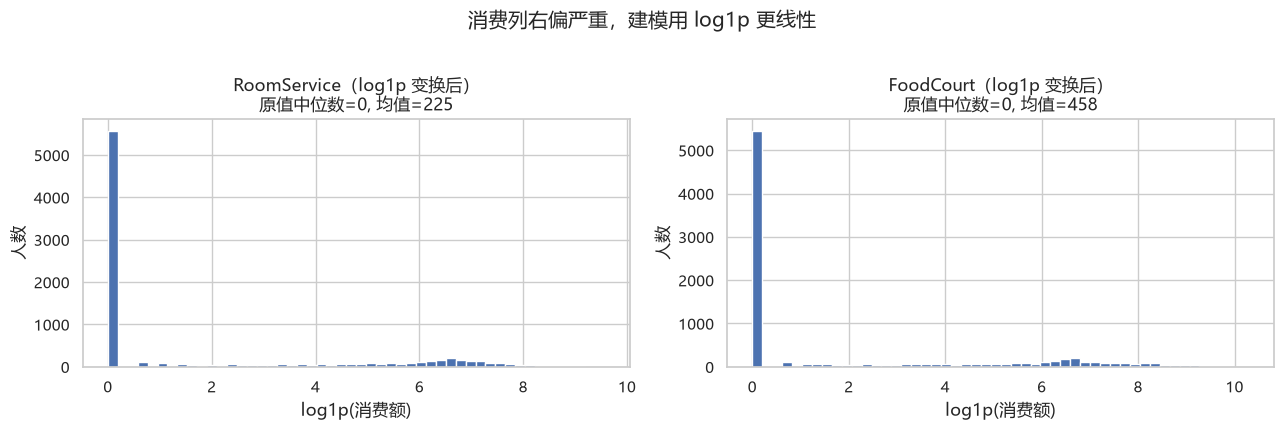

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col in zip(axes, ["RoomService", "FoodCourt"]):
    non = train_raw[col].dropna()
    ax.hist(np.log1p(non), bins=50, color="#4C72B0")
    ax.set_title(f"{col}（log1p 变换后）\n原值中位数={non.median():.0f}, 均值={non.mean():.0f}")
    ax.set_xlabel("log1p(消费额)")
    ax.set_ylabel("人数")
plt.suptitle("消费列右偏严重，建模用 log1p 更线性", y=1.02)
plt.tight_layout()
fig.savefig(FIG / "01_spend_distribution.png", dpi=140, bbox_inches="tight")
plt.show()



## 1.7 体检结论
**规模与类型**
- train 8693 × 14、test 4277 × 13，与题目描述一致；两表 dtype 一致。
- `CryoSleep` / `VIP` 是 `object` 三态列（True/False/缺失），不是 `bool`。
**重复记录**
- 整行重复 0、`PassengerId` 重复 0、列名重复 0 —— 无需去重。
**缺失**
- 每列缺失率都在 2% 上下，非常均匀；含缺失的行 2087 / 8693（24.0%）。
- 缺失**几乎不共现**（列间缺失相关最高约 0.03），不存在"某类乘客整块缺"的结构。
  这点很重要：意味着"缺失本身携带的信息量很低"，缺失指示位大概率帮助有限——
  这一点会在 notebook 03 用实验确认，而不是直接下结论。
**组内一致性（与常见说法不同的地方）**
- `HomePlanet`、`Cabin.Side` 组内恒定 → 可当组级属性，可用来补缺。
- `Destination`、`Cabin.Deck`、`CabinNum` 组内**可以不同** → 不能当组级属性。
- 同姓氏 ≠ 同组：2217 个姓氏中 1664 个跨多个组。姓氏与组号是两套互补信息。
**异常**
- `Age==0` 有 178 人，是婴儿（与同组成人年龄连贯），**不是脏数据**，不要删。
- 消费列无负值，右偏严重、中位数为 0 → 适合 `log1p` + 零值标志位。
- `CryoSleep=True ⇒ 消费恒为 0` 完全成立（3037 人零例外）；反过来"消费>0 ⇒ 非冷冻"
  也成立，可以直接用来补 119 个缺失的 `CryoSleep`。
- `Deck='T'` 仅 5 人，属极稀有类别。
**下一步**：把这份体检结论变成 notebook 02 的关系分析，和 notebook 03 的补缺方案。
